# 04 - Modelagem preditiva

## 1. Objetivo do notebook

Este notebook tem como objetivo preparar os dados e desenvolver os modelos preditivos para estimar a precipitação diária da estação A701.

A modelagem será construída a partir dos resultados obtidos na análise exploratória. Serão consideradas informações temporais da própria série, características sazonais e variáveis meteorológicas auxiliares.

Os modelos serão avaliados respeitando a ordem cronológica dos dados, evitando o uso de informações futuras durante o treinamento e permitindo uma comparação consistente entre diferentes estratégias de previsão.

## 2. Carregamento da base diária

A modelagem utiliza como ponto de partida a base diária consolidada na camada Gold, produzida após as etapas de controle de qualidade e pré-processamento.

Nesta etapa, a base é carregada e sua estrutura é verificada antes da criação das variáveis utilizadas pelos modelos.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

caminho_gold = Path("../data/gold/a701_2010_2025_diario.parquet")

df = pd.read_parquet(caminho_gold)

df.head()

,DATA (YYYY-MM-DD),horas_validas,precipitacao_diaria_mm,dia_completo,temperatura_media,temperatura_media_horas_validas,umidade_media,umidade_media_horas_validas,pressao_media,pressao_media_horas_validas,vento_medio,vento_medio_horas_validas
0,2010-01-01,24,6.8,True,21.333333,24,86.916667,24,923.025000,24,2.329167,24
1,2010-01-02,24,36.2,True,22.166667,24,83.833333,24,925.041667,24,1.079167,24
2,2010-01-03,24,0.8,True,24.229167,24,78.625000,24,926.712500,24,1.433333,24
3,2010-01-04,24,13.4,True,24.241667,24,74.500000,24,926.695833,24,2.004167,24
4,2010-01-05,24,20.8,True,24.845833,24,72.666667,24,924.004167,24,1.762500,24


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5844 entries, 0 to 5843
Data columns (total 12 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   DATA (YYYY-MM-DD)                5844 non-null   datetime64[us]
 1   horas_validas                    5844 non-null   int64         
 2   precipitacao_diaria_mm           5655 non-null   float64       
 3   dia_completo                     5844 non-null   bool          
 4   temperatura_media                5802 non-null   float64       
 5   temperatura_media_horas_validas  5844 non-null   int64         
 6   umidade_media                    5809 non-null   float64       
 7   umidade_media_horas_validas      5844 non-null   int64         
 8   pressao_media                    5809 non-null   float64       
 9   pressao_media_horas_validas      5844 non-null   int64         
 10  vento_medio                      5809 non-null   float64       
 11  ve

In [4]:
print("Quantidade de registros:", len(df))
print("Data inicial:", df["DATA (YYYY-MM-DD)"].min())
print("Data final:", df["DATA (YYYY-MM-DD)"].max())

Quantidade de registros: 5844
Data inicial: 2010-01-01 00:00:00
Data final: 2025-12-31 00:00:00


## 3. Engenharia de atributos

A engenharia de atributos transforma informações disponíveis na série histórica em variáveis que possam ser utilizadas pelos modelos preditivos.

As variáveis desta etapa serão definidas com base nos resultados da análise exploratória. Foram identificados comportamento sazonal ao longo do ano, dependência temporal de curto prazo na precipitação e associações entre a chuva e variáveis meteorológicas auxiliares.

Por esse motivo, serão avaliados três grupos principais de atributos:

- atributos temporais e sazonais;
- valores anteriores da precipitação (lags);
- variáveis meteorológicas auxiliares.

A construção dessas variáveis deverá respeitar a ordem temporal da série, evitando o uso de informações futuras na previsão.

### 3.1 Atributos temporais

In [5]:
df["mes"] = df["DATA (YYYY-MM-DD)"].dt.month
df["dia_ano"] = df["DATA (YYYY-MM-DD)"].dt.dayofyear

In [6]:
df[
    [
        "DATA (YYYY-MM-DD)",
        "mes",
        "dia_ano"
    ]
].head(10)

,DATA (YYYY-MM-DD),mes,dia_ano
0,2010-01-01,1,1
1,2010-01-02,1,2
2,2010-01-03,1,3
3,2010-01-04,1,4
4,2010-01-05,1,5
5,2010-01-06,1,6
6,2010-01-07,1,7
7,2010-01-08,1,8
8,2010-01-09,1,9
9,2010-01-10,1,10


In [7]:
df["mes_sin"] = np.sin(2 * np.pi * df["mes"] / 12)
df["mes_cos"] = np.cos(2 * np.pi * df["mes"] / 12)

In [8]:
df["dia_ano_sin"] = np.sin(2 * np.pi * df["dia_ano"] / 365.25)
df["dia_ano_cos"] = np.cos(2 * np.pi * df["dia_ano"] / 365.25)

In [9]:
df[
    [
        "DATA (YYYY-MM-DD)",
        "mes",
        "mes_sin",
        "mes_cos",
        "dia_ano",
        "dia_ano_sin",
        "dia_ano_cos"
    ]
].head()

,DATA (YYYY-MM-DD),mes,mes_sin,mes_cos,dia_ano,dia_ano_sin,dia_ano_cos
0,2010-01-01,1,0.5,0.866025,1,0.017202,0.999852
1,2010-01-02,1,0.5,0.866025,2,0.034398,0.999408
2,2010-01-03,1,0.5,0.866025,3,0.051584,0.998669
3,2010-01-04,1,0.5,0.866025,4,0.068755,0.997634
4,2010-01-05,1,0.5,0.866025,5,0.085906,0.996303


In [10]:
df["precipitacao_lag_1"] = df["precipitacao_diaria_mm"].shift(1)
df["precipitacao_lag_2"] = df["precipitacao_diaria_mm"].shift(2)
df["precipitacao_lag_3"] = df["precipitacao_diaria_mm"].shift(3)

In [11]:
df[
    [
        "DATA (YYYY-MM-DD)",
        "precipitacao_diaria_mm",
        "precipitacao_lag_1",
        "precipitacao_lag_2",
        "precipitacao_lag_3"
    ]
].head(10)

,DATA (YYYY-MM-DD),precipitacao_diaria_mm,precipitacao_lag_1,precipitacao_lag_2,precipitacao_lag_3
0,2010-01-01,6.8,NaN,NaN,NaN
1,2010-01-02,36.2,6.8,NaN,NaN
2,2010-01-03,0.8,36.2,6.8,NaN
3,2010-01-04,13.4,0.8,36.2,6.8
4,2010-01-05,20.8,13.4,0.8,36.2
5,2010-01-06,37.4,20.8,13.4,0.8
6,2010-01-07,0.2,37.4,20.8,13.4
7,2010-01-08,30.2,0.2,37.4,20.8
8,2010-01-09,0.2,30.2,0.2,37.4
9,2010-01-10,0.6,0.2,30.2,0.2


In [12]:
df[
    [
        "precipitacao_lag_1",
        "precipitacao_lag_2",
        "precipitacao_lag_3"
    ]
].isna().sum()

precipitacao_lag_1    190
precipitacao_lag_2    191
precipitacao_lag_3    192
dtype: int64

### Ausências geradas pelas defasagens

A criação das variáveis defasadas preservou as ausências existentes na série original. Além dos 189 dias com precipitação indisponível, cada lag adiciona ausências no início da série, pois não existem observações anteriores suficientes nesses primeiros registros.

Dessa forma, foram observados 190 valores ausentes no `lag 1`, 191 no `lag 2` e 192 no `lag 3`.

Esses valores não serão substituídos por zero, pois ausência de informação não representa ausência de precipitação.

In [13]:
df["media_movel_3"] = (
    df["precipitacao_diaria_mm"]
    .shift(1)
    .rolling(window=3)
    .mean()
)

df["media_movel_7"] = (
    df["precipitacao_diaria_mm"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

In [14]:
df[
    [
        "DATA (YYYY-MM-DD)",
        "precipitacao_diaria_mm",
        "media_movel_3",
        "media_movel_7"
    ]
].head(12)

,DATA (YYYY-MM-DD),precipitacao_diaria_mm,media_movel_3,media_movel_7
0,2010-01-01,6.8,NaN,NaN
1,2010-01-02,36.2,NaN,NaN
2,2010-01-03,0.8,NaN,NaN
3,2010-01-04,13.4,14.600000,NaN
4,2010-01-05,20.8,16.800000,NaN
5,2010-01-06,37.4,11.666667,NaN
6,2010-01-07,0.2,23.866667,NaN
7,2010-01-08,30.2,19.466667,16.514286
8,2010-01-09,0.2,22.600000,19.857143
9,2010-01-10,0.6,10.200000,14.714286


In [15]:
df[
    [
        "media_movel_3",
        "media_movel_7"
    ]
].isna().sum()

media_movel_3    440
media_movel_7    815
dtype: int64

In [16]:
colunas_modelagem = [
    "precipitacao_diaria_mm",
    "precipitacao_lag_1",
    "precipitacao_lag_2",
    "precipitacao_lag_3",
    "media_movel_3",
    "media_movel_7",
    "temperatura_media",
    "umidade_media",
    "pressao_media",
    "vento_medio"
]

linhas_completas = df[colunas_modelagem].dropna()

print("Total de dias da série:", len(df))
print("Dias completos para modelagem:", len(linhas_completas))
print("Dias excluídos por alguma ausência:", len(df) - len(linhas_completas))

Total de dias da série: 5844
Dias completos para modelagem: 4954
Dias excluídos por alguma ausência: 890


### Impacto das ausências nas variáveis de modelagem

A combinação entre a variável-alvo, defasagens, médias móveis e variáveis meteorológicas auxiliares resultou em 4.954 dias com todas as informações disponíveis para modelagem, dos 5.844 dias da série original.

Isso corresponde à retenção de aproximadamente 84,8% dos registros. A redução ocorre principalmente porque as médias móveis exigem histórico completo dentro de suas respectivas janelas e propagam temporariamente as ausências existentes na série de precipitação.

Apesar dessa perda, o volume restante de observações foi considerado suficiente para manter inicialmente as janelas móveis de 3 e 7 dias, cuja contribuição será avaliada posteriormente pelo desempenho dos modelos.

## 4. Definição do horizonte de previsão

O experimento será estruturado como uma previsão de um dia à frente. Para cada data-alvo, o modelo deverá estimar a precipitação diária utilizando somente informações disponíveis até o dia anterior.

Essa definição é importante para evitar vazamento de informação. Variáveis meteorológicas observadas no próprio dia da precipitação-alvo não podem ser utilizadas diretamente, pois seus valores completos somente seriam conhecidos após o encerramento desse dia.

Dessa forma, as variáveis históricas de precipitação e as variáveis meteorológicas auxiliares serão organizadas de modo que apenas informações passadas sejam utilizadas para prever o dia seguinte. As informações de calendário da data-alvo, por outro lado, podem ser utilizadas diretamente, pois são conhecidas antecipadamente.

In [17]:
df["temperatura_lag_1"] = df["temperatura_media"].shift(1)
df["umidade_lag_1"] = df["umidade_media"].shift(1)
df["pressao_lag_1"] = df["pressao_media"].shift(1)
df["vento_lag_1"] = df["vento_medio"].shift(1)

In [18]:
df[
    [
        "DATA (YYYY-MM-DD)",
        "precipitacao_diaria_mm",
        "temperatura_media",
        "temperatura_lag_1",
        "umidade_media",
        "umidade_lag_1"
    ]
].head(5)

,DATA (YYYY-MM-DD),precipitacao_diaria_mm,temperatura_media,temperatura_lag_1,umidade_media,umidade_lag_1
0,2010-01-01,6.8,21.333333,NaN,86.916667,NaN
1,2010-01-02,36.2,22.166667,21.333333,83.833333,86.916667
2,2010-01-03,0.8,24.229167,22.166667,78.625000,83.833333
3,2010-01-04,13.4,24.241667,24.229167,74.500000,78.625000
4,2010-01-05,20.8,24.845833,24.241667,72.666667,74.500000


### Defasagem das variáveis meteorológicas auxiliares

As variáveis meteorológicas auxiliares foram deslocadas em um dia para representar um cenário de previsão de curto prazo.

Dessa forma, para estimar a precipitação de uma determinada data, o modelo utiliza os valores de temperatura, umidade, pressão e vento observados no dia anterior, evitando o uso de informações contemporâneas ao alvo.

Esse procedimento reduz o risco de vazamento de informação e mantém o experimento compatível com uma previsão de um dia à frente.

## 5. Definição dos cenários de modelagem

A comparação dos modelos será realizada em cenários com diferentes níveis de informação disponível.

O primeiro cenário utilizará apenas atributos temporais e históricos da própria precipitação. O segundo acrescentará variáveis meteorológicas auxiliares observadas no dia anterior. Essa separação permitirá avaliar se a inclusão das variáveis meteorológicas contribui para reduzir o erro de previsão em relação ao uso apenas do histórico da série.

In [19]:
features_temporais = [
    "mes_sin",
    "mes_cos",
    "dia_ano_sin",
    "dia_ano_cos",
    "precipitacao_lag_1",
    "precipitacao_lag_2",
    "precipitacao_lag_3",
    "media_movel_3",
    "media_movel_7"
]

features_multivariadas = features_temporais + [
    "temperatura_lag_1",
    "umidade_lag_1",
    "pressao_lag_1",
    "vento_lag_1"
]

alvo = "precipitacao_diaria_mm"

In [20]:
df_temporal = df[[alvo] + features_temporais].dropna()

df_multivariado = df[[alvo] + features_multivariadas].dropna()

print("Cenário temporal:")
print("Registros disponíveis:", len(df_temporal))

print("\nCenário multivariado:")
print("Registros disponíveis:", len(df_multivariado))

Cenário temporal:
Registros disponíveis: 4961

Cenário multivariado:
Registros disponíveis: 4954


### Base comum para comparação dos cenários

Os cenários temporal e multivariado apresentaram quantidade semelhante de observações disponíveis: 4.961 e 4.954 registros, respectivamente.

Para garantir uma comparação consistente entre os modelos, será utilizada uma base comum contendo apenas as datas em que todas as variáveis necessárias ao cenário multivariado estão disponíveis.

Dessa forma, os diferentes cenários serão treinados e avaliados sobre o mesmo conjunto de datas, evitando que diferenças nas métricas sejam causadas por amostras distintas.

In [21]:
colunas_base_comum = [
    "DATA (YYYY-MM-DD)",
    alvo
] + features_multivariadas

base_modelagem = (
    df[colunas_base_comum]
    .dropna()
    .copy()
)

print("Registros na base comum:", len(base_modelagem))
print("Data inicial:", base_modelagem["DATA (YYYY-MM-DD)"].min())
print("Data final:", base_modelagem["DATA (YYYY-MM-DD)"].max())

Registros na base comum: 4954
Data inicial: 2010-01-08 00:00:00
Data final: 2025-12-31 00:00:00


## 6. Divisão temporal dos dados

Os dados serão divididos em conjuntos de treinamento e teste mantendo a ordem cronológica das observações.

Os 80% registros mais antigos serão utilizados para treinamento dos modelos, enquanto os 20% mais recentes serão reservados para avaliação final.

Diferentemente de uma divisão aleatória convencional, não haverá embaralhamento dos registros, pois o objetivo é reproduzir uma situação real de previsão, na qual informações futuras não estão disponíveis durante o treinamento.

O conjunto de teste corresponde, portanto, ao período cronologicamente mais recente da série e será utilizado para avaliar a capacidade de generalização dos modelos fora do período utilizado no treinamento.

In [29]:
indice_corte = int(len(base_modelagem) * 0.8)

treino = base_modelagem.iloc[:indice_corte].copy()
teste = base_modelagem.iloc[indice_corte:].copy()

print("Total:", len(base_modelagem))
print("Treino:", len(treino))
print("Teste:", len(teste))

print("\nPeríodo de treino:")
print(
    treino["DATA (YYYY-MM-DD)"].min(),
    "até",
    treino["DATA (YYYY-MM-DD)"].max()
)

print("\nPeríodo de teste:")
print(
    teste["DATA (YYYY-MM-DD)"].min(),
    "até",
    teste["DATA (YYYY-MM-DD)"].max()
)

Total: 4954
Treino: 3963
Teste: 991

Período de treino:
2010-01-08 00:00:00 até 2022-01-12 00:00:00

Período de teste:
2022-01-13 00:00:00 até 2025-12-31 00:00:00


In [31]:
target = "precipitacao_diaria_mm"

y_train = treino[target].copy()
y_test = teste[target].copy()

In [32]:
features_temporais = [
    "mes_sin",
    "mes_cos",
    "dia_ano_sin",
    "dia_ano_cos",
    "precipitacao_lag_1",
    "precipitacao_lag_2",
    "precipitacao_lag_3",
    "media_movel_3",
    "media_movel_7"
]

features_multivariadas = features_temporais + [
    "temperatura_lag_1",
    "umidade_lag_1",
    "pressao_lag_1",
    "vento_lag_1"
]

In [33]:
X_train_temporal = treino[features_temporais].copy()
X_test_temporal = teste[features_temporais].copy()

X_train_multivariado = treino[features_multivariadas].copy()
X_test_multivariado = teste[features_multivariadas].copy()

In [34]:
print("Temporal")
print("X_train:", X_train_temporal.shape)
print("X_test:", X_test_temporal.shape)

print("\nMultivariado")
print("X_train:", X_train_multivariado.shape)
print("X_test:", X_test_multivariado.shape)

print("\nTarget")
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Temporal
X_train: (3963, 9)
X_test: (991, 9)

Multivariado
X_train: (3963, 13)
X_test: (991, 13)

Target
y_train: (3963,)
y_test: (991,)


In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_pred_baseline = X_test_temporal["precipitacao_lag_1"]

mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
rmse_baseline = np.sqrt(
    mean_squared_error(y_test, y_pred_baseline)
)

print("Baseline - Persistência")
print(f"MAE: {mae_baseline:.3f} mm")
print(f"RMSE: {rmse_baseline:.3f} mm")

Baseline - Persistência
MAE: 5.455 mm
RMSE: 11.622 mm


### Baseline de persistência

Como referência inicial, foi utilizado um modelo de persistência, no qual a precipitação prevista para o dia seguinte corresponde à precipitação observada no dia anterior.

No conjunto de teste, o baseline apresentou MAE de 5,455 mm e RMSE de 11,622 mm. Esses valores serão utilizados como referência para avaliar se modelos mais complexos apresentam ganho preditivo relevante.

A dispersão entre valores observados e previstos indica que a Regressão Linear apresenta tendência de subestimação dos eventos de maior precipitação. Embora o modelo reduza o RMSE em relação ao baseline de persistência, sua capacidade de representar eventos extremos permanece limitada.

In [48]:
predicoes_validacao_temporal = []
reais_validacao_temporal = []
indices_validacao_temporal = []

for idx_train, idx_val in tscv.split(X_train_temporal):

    X_tr = X_train_temporal.iloc[idx_train]
    X_val = X_train_temporal.iloc[idx_val]

    y_tr = y_train.iloc[idx_train]
    y_val = y_train.iloc[idx_val]

    modelo = LinearRegression()
    modelo.fit(X_tr, y_tr)

    y_pred = modelo.predict(X_val)

    predicoes_validacao_temporal.extend(y_pred)
    reais_validacao_temporal.extend(y_val.values)
    indices_validacao_temporal.extend(idx_val)

In [49]:
predicoes_validacao_temporal = np.array(
    predicoes_validacao_temporal
)

reais_validacao_temporal = np.array(
    reais_validacao_temporal
)

indices_validacao_temporal = np.array(
    indices_validacao_temporal
)

print("Valores reais:", len(reais_validacao_temporal))
print("Previsões:", len(predicoes_validacao_temporal))

Valores reais: 3300
Previsões: 3300


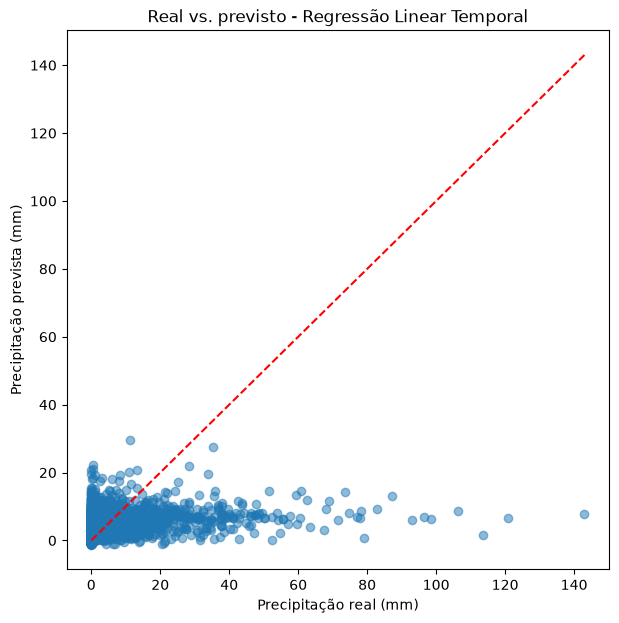

In [50]:
plt.figure(figsize=(7, 7))

plt.scatter(
    reais_validacao_temporal,
    predicoes_validacao_temporal,
    alpha=0.5
)

limite = max(
    reais_validacao_temporal.max(),
    predicoes_validacao_temporal.max()
)

plt.plot(
    [0, limite],
    [0, limite],
    linestyle="--",
    color="red"
)

plt.xlabel("Precipitação real (mm)")
plt.ylabel("Precipitação prevista (mm)")
plt.title("Real vs. previsto - Regressão Linear Temporal")

plt.show()

A dispersão entre os valores observados e previstos na validação temporal mostra que a Regressão Linear apresenta dificuldade em representar eventos de precipitação elevada. À medida que os valores observados aumentam, as previsões permanecem concentradas em níveis mais baixos, indicando tendência de subestimação dos eventos mais intensos.

Esse comportamento é coerente com a natureza assimétrica da variável de precipitação, caracterizada por grande concentração de dias com pouca ou nenhuma chuva e menor ocorrência de eventos extremos.

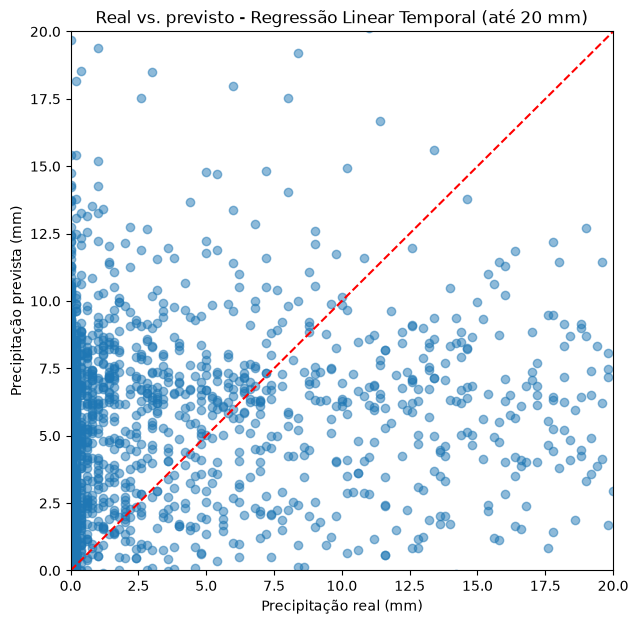

In [51]:
plt.figure(figsize=(7, 7))

mascara_zoom = reais_validacao_temporal <= 20

plt.scatter(
    reais_validacao_temporal[mascara_zoom],
    predicoes_validacao_temporal[mascara_zoom],
    alpha=0.5
)

plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--",
    color="red"
)

plt.xlim(0, 20)
plt.ylim(0, 20)

plt.xlabel("Precipitação real (mm)")
plt.ylabel("Precipitação prevista (mm)")
plt.title("Real vs. previsto - Regressão Linear Temporal (até 20 mm)")

plt.show()

In [53]:
predicoes_validacao_multi = []
reais_validacao_multi = []

for idx_train, idx_val in tscv.split(X_train_multivariado):

    X_tr = X_train_multivariado.iloc[idx_train]
    X_val = X_train_multivariado.iloc[idx_val]

    y_tr = y_train.iloc[idx_train]
    y_val = y_train.iloc[idx_val]

    modelo = LinearRegression()
    modelo.fit(X_tr, y_tr)

    y_pred = modelo.predict(X_val)

    predicoes_validacao_multi.extend(y_pred)
    reais_validacao_multi.extend(y_val.values)

predicoes_validacao_multi = np.array(predicoes_validacao_multi)
reais_validacao_multi = np.array(reais_validacao_multi)

print("Valores reais:", len(reais_validacao_multi))
print("Previsões:", len(predicoes_validacao_multi))

Valores reais: 3300
Previsões: 3300


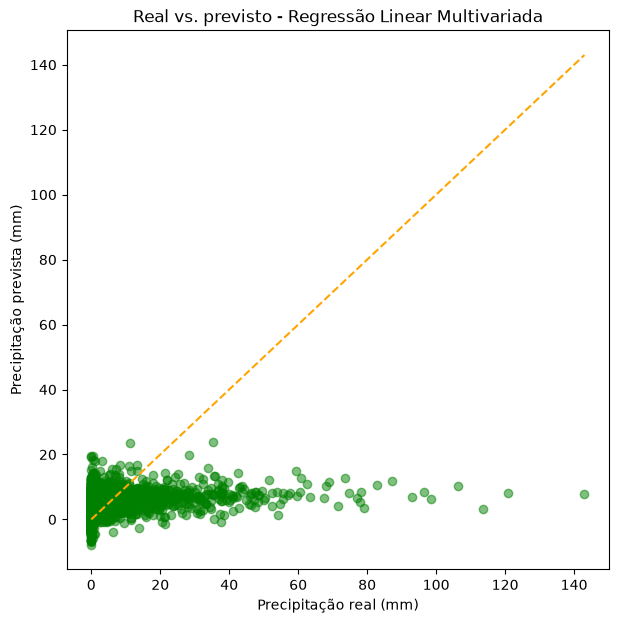

In [55]:
plt.figure(figsize=(7, 7))

plt.scatter(
    reais_validacao_multi,
    predicoes_validacao_multi,
    alpha=0.5,
    color="green"
)

limite = max(
    reais_validacao_multi.max(),
    predicoes_validacao_multi.max()
)

plt.plot(
    [0, limite],
    [0, limite],
    linestyle="--",
    color="orange"
)

plt.xlabel("Precipitação real (mm)")
plt.ylabel("Precipitação prevista (mm)")
plt.title("Real vs. previsto - Regressão Linear Multivariada")

plt.show()

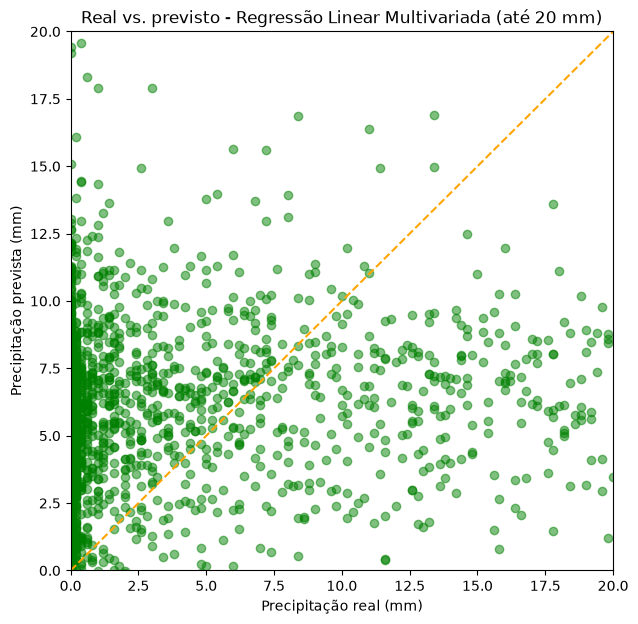

In [57]:
plt.figure(figsize=(7, 7))

mascara_zoom = reais_validacao_multi <= 20

plt.scatter(
    reais_validacao_multi[mascara_zoom],
    predicoes_validacao_multi[mascara_zoom],
    alpha=0.5,
    color="green"
)

plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--",
    color="orange"
)

plt.xlim(0, 20)
plt.ylim(0, 20)

plt.xlabel("Precipitação real (mm)")
plt.ylabel("Precipitação prevista (mm)")
plt.title("Real vs. previsto - Regressão Linear Multivariada (até 20 mm)")

plt.show()

No cenário multivariado, a inclusão das variáveis meteorológicas auxiliares produziu pequena melhora nas métricas médias de validação, mas não alterou de forma substancial o padrão das previsões.

A dispersão continuou indicando tendência de concentração das estimativas em valores moderados e subestimação dos eventos de maior precipitação, evidenciando uma limitação da Regressão Linear para representar a assimetria e os extremos da série.